In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams['figure.figsize'] = (10, 5)

# Load cleaned dataset
df = pd.read_csv('01_cleaned_data.csv')
print("Dataset Shape:", df.shape)
df.head()


Dataset Shape: (100000, 25)


,Order_ID,Customer_ID,Customer_Age,Customer_Gender,City,Area,Restaurant_ID,Restaurant_Name,Cuisine_Type,Order_Date,...,Final_Amount,Payment_Mode,Order_Status,Cancellation_Reason,Delivery_Partner_ID,Delivery_Rating,Restaurant_Rating,Order_Day,Peak_Hour,Profit_Margin
0,ORD000001,CUST6948,19.0,Male,Hyderabad,Central,RES936,Restaurant_29,Chinese,2024-10-20,...,1147.0,Upi,Delivered,NaN,DP563,5.0,4.4,Weekend,True,0.13
1,ORD000002,CUST6515,39.0,Female,Chennai,North,RES689,Restaurant_419,Chinese,2024-08-12,...,4849.0,Cod,Delivered,NaN,DP369,5.0,4.7,Weekday,True,0.48
2,ORD000003,CUST1765,39.0,Male,Delhi,South,RES723,Restaurant_244,Arabian,2024-12-08,...,737.0,Wallet,Delivered,NaN,DP580,4.0,4.9,Weekend,True,0.08
3,ORD000004,CUST2744,39.0,Male,Mumbai,Central,RES951,Restaurant_178,Chinese,2024-10-08,...,1147.0,Upi,Cancelled,Late Delivery,DP155,NaN,3.4,Weekday,False,0.04
4,ORD000005,CUST4389,57.0,Female,Chennai,South,RES419,Restaurant_262,Chinese,2024-02-04,...,352.0,Card,Delivered,NaN,DP728,2.0,4.4,Weekend,False,0.12


In [3]:
# 1. Summary Statistics (Numerical & Categorical)
print("=== Numerical Summary ===")
display(df.describe().round(2))

print("\n=== Categorical Summary ===")
display(df.describe(include=['object', 'bool']))


=== Numerical Summary ===


,Customer_Age,Delivery_Time_Min,Distance_km,Order_Value,Discount_Applied,Final_Amount,Delivery_Rating,Restaurant_Rating,Profit_Margin
count,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,84964.00,100000.00,100000.00
mean,38.99,124.98,14.28,1786.94,86.59,1700.95,2.99,4.20,0.25
std,8.74,74.21,10.45,1335.40,100.10,1338.26,1.29,0.65,0.12
min,18.00,20.00,1.00,150.00,0.00,0.00,1.00,3.00,0.00
25%,39.00,58.00,7.76,935.00,20.00,847.00,2.00,3.60,0.17
50%,39.00,120.00,9.97,1197.00,50.00,1147.00,3.00,4.20,0.25
75%,39.00,165.00,21.13,2743.00,100.00,2655.00,4.00,4.90,0.32
max,60.00,300.00,40.00,5000.00,300.00,5000.00,5.00,5.00,0.50



=== Categorical Summary ===


C:\Users\acer\AppData\Local\Temp\ipykernel_19316\2799185201.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(df.describe(include=['object', 'bool']))


,Order_ID,Customer_ID,Customer_Gender,City,Area,Restaurant_ID,Restaurant_Name,Cuisine_Type,Order_Date,Order_Time,Payment_Mode,Order_Status,Cancellation_Reason,Delivery_Partner_ID,Order_Day,Peak_Hour
count,100000,100000,100000,100000,100000,100000,100000,100000,100000,100000,100000,100000,15036,100000,100000,100000
unique,100000,8999,3,5,5,900,500,5,365,1,4,2,4,900,2,2
top,ORD000001,CUST2487,Other,Hyderabad,South,RES509,Restaurant_450,Indian,2024-07-15,0:00,Card,Delivered,Unspecified,DP543,Weekday,False
freq,1,24,49991,33610,33410,145,246,33570,323,100000,40005,84964,6005,144,71370,66547


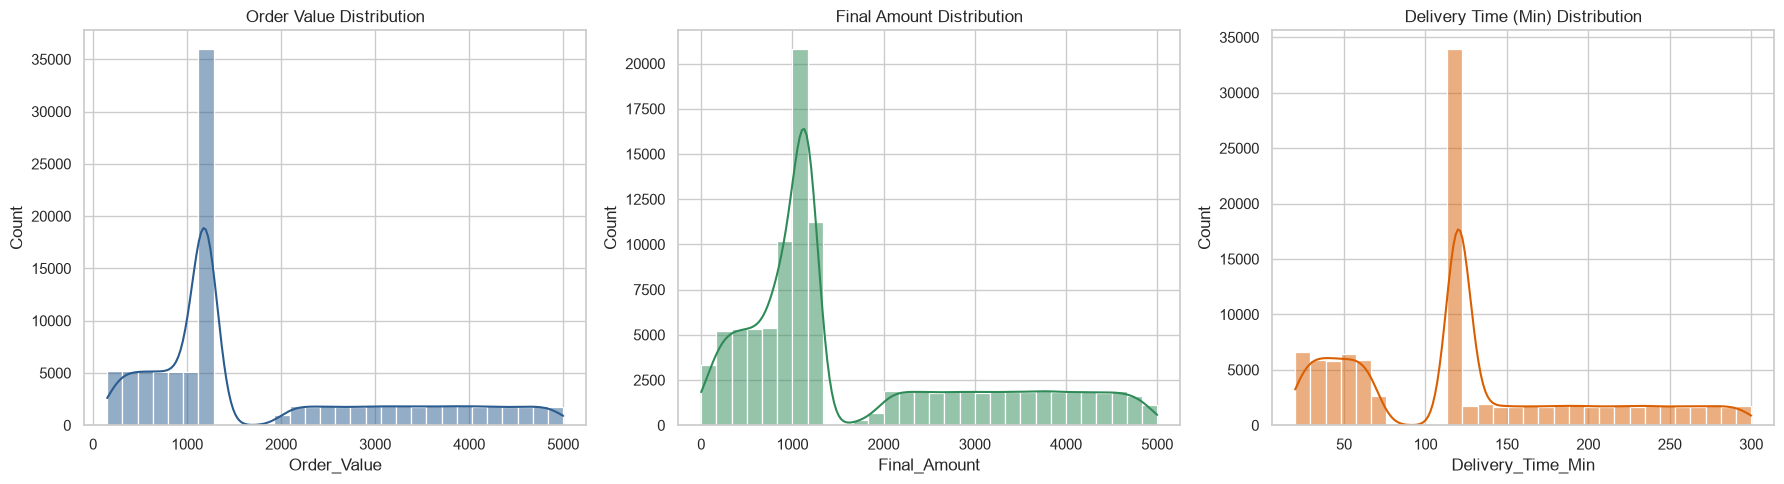

In [4]:
# 2. Distribution of Order Values, Final Amount & Delivery Time
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(df['Order_Value'], bins=30, kde=True, ax=axes[0], color='#2b5c8f')
axes[0].set_title('Order Value Distribution')

sns.histplot(df['Final_Amount'], bins=30, kde=True, ax=axes[1], color='#2e8b57')
axes[1].set_title('Final Amount Distribution')

sns.histplot(df['Delivery_Time_Min'], bins=30, kde=True, ax=axes[2], color='#d95f02')
axes[2].set_title('Delivery Time (Min) Distribution')

plt.tight_layout()
plt.show()


C:\Users\acer\AppData\Local\Temp\ipykernel_19316\1109663401.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=city_counts.index, y=city_counts.values, ax=axes[0], palette='Blues_r')
C:\Users\acer\AppData\Local\Temp\ipykernel_19316\1109663401.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cuisine_counts.index, y=cuisine_counts.values, ax=axes[1], palette='Greens_r')


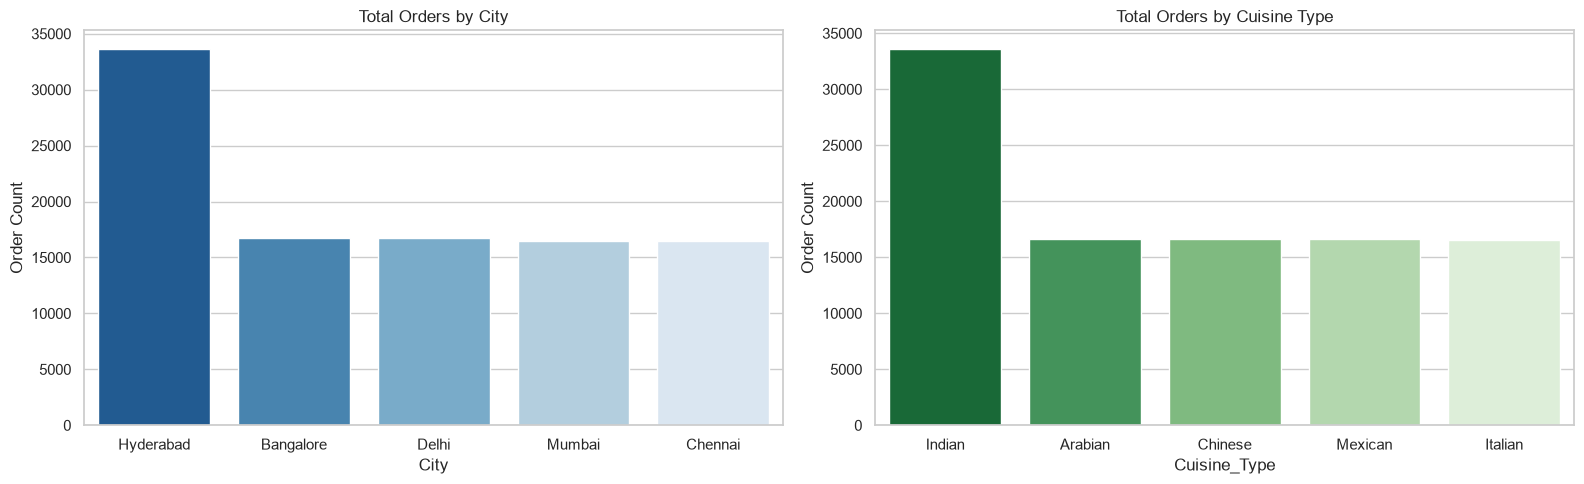

In [5]:
# 3. City-wise & Cuisine-wise Order Analysis
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

city_counts = df['City'].value_counts()
sns.barplot(x=city_counts.index, y=city_counts.values, ax=axes[0], palette='Blues_r')
axes[0].set_title('Total Orders by City')
axes[0].set_ylabel('Order Count')

cuisine_counts = df['Cuisine_Type'].value_counts()
sns.barplot(x=cuisine_counts.index, y=cuisine_counts.values, ax=axes[1], palette='Greens_r')
axes[1].set_title('Total Orders by Cuisine Type')
axes[1].set_ylabel('Order Count')

plt.tight_layout()
plt.show()


C:\Users\acer\AppData\Local\Temp\ipykernel_19316\2639248006.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y='Cancellation_Reason', data=cancelled_df, order=cancelled_df['Cancellation_Reason'].value_counts().index, ax=axes[1], palette='Reds_r')
C:\Users\acer\AppData\Local\Temp\ipykernel_19316\2639248006.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Payment_Mode', data=df, order=df['Payment_Mode'].value_counts().index, ax=axes[2], palette='Purples_r')


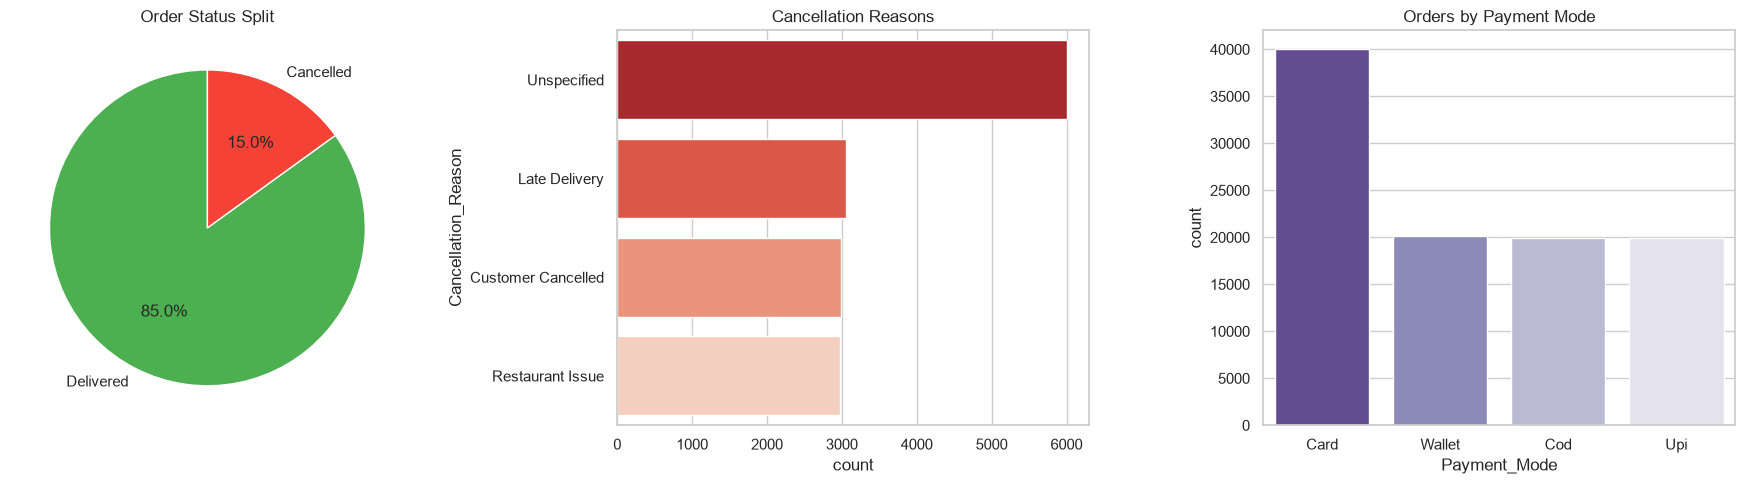

In [6]:
# 4. Order Status, Cancellation Reasons & Payment Mode Breakdown
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

df['Order_Status'].value_counts().plot.pie(autopct='%1.1f%%', ax=axes[0], colors=['#4caf50', '#f44336'], startangle=90)
axes[0].set_title('Order Status Split')
axes[0].set_ylabel('')

cancelled_df = df[df['Order_Status'] == 'Cancelled']
sns.countplot(y='Cancellation_Reason', data=cancelled_df, order=cancelled_df['Cancellation_Reason'].value_counts().index, ax=axes[1], palette='Reds_r')
axes[1].set_title('Cancellation Reasons')

sns.countplot(x='Payment_Mode', data=df, order=df['Payment_Mode'].value_counts().index, ax=axes[2], palette='Purples_r')
axes[2].set_title('Orders by Payment Mode')

plt.tight_layout()
plt.show()


C:\Users\acer\AppData\Local\Temp\ipykernel_19316\2104526385.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='City', y='Delivery_Time_Min', data=df, ax=axes[0], palette='Set2')


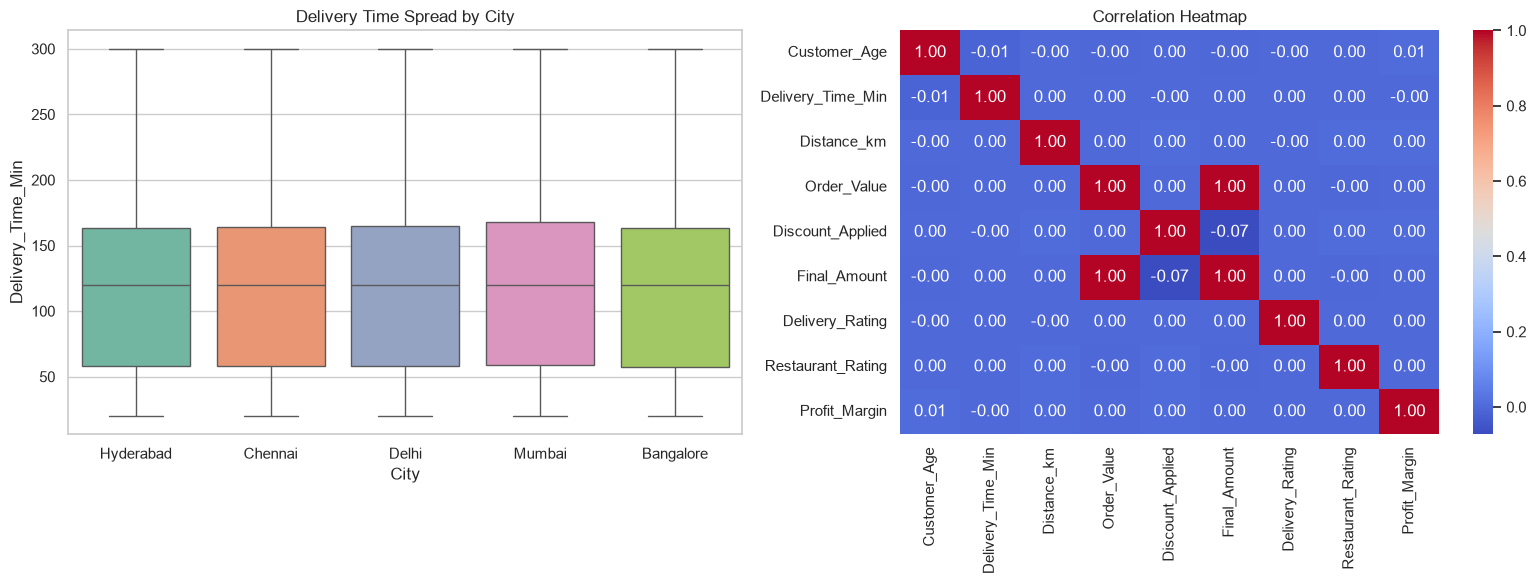

In [7]:
# 5. Outlier Boxplots & Correlation Heatmap
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.boxplot(x='City', y='Delivery_Time_Min', data=df, ax=axes[0], palette='Set2')
axes[0].set_title('Delivery Time Spread by City')

num_cols = ['Customer_Age', 'Delivery_Time_Min', 'Distance_km', 'Order_Value', 'Discount_Applied', 'Final_Amount', 'Delivery_Rating', 'Restaurant_Rating', 'Profit_Margin']
corr = df[num_cols].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', ax=axes[1])
axes[1].set_title('Correlation Heatmap')

plt.tight_layout()
plt.show()
